# 面包店数据探索性分析

数据模型：`购买记录` 是唯一事实表，`商品原料信息` 与 `日期维度表` 是维度表；
Excel 里已有的结果表不参与计算。

运行前请 `pip install -r requirements.txt`，把数据放到 `data/raw/food.xlsx`（不存在时自动用样例数据）。

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

import pandas as pd
from src import config, load, clean, derive, analysis, run_all

pd.set_option("display.unicode.east_asian_width", True)
pd.set_option("display.max_columns", 40)

frames = load.load_all()
frames = clean.clean_all(frames)
print("数据源:", frames["_source"].iloc[0, 0])
print("已忽略:", "、".join(frames["_ignored"]["sheet"]))
results = run_all.build_results(frames)

数据源: E:\projects\bakery-sales-analysis\data\sample\sample_food.xlsx
已忽略: 原料消耗、单日产品销售量、客流量、原料采购、口味偏好、产品偏好、字段分析建议、产品生产


## 1. 销售概览

In [2]:
results["销售概览"]

,指标,数值
0,数据区间,2026-08-01 ~ 2026-10-31
1,营业天数,92
2,订单数,"6,161"
3,顾客数（去重身份id）,"4,091"
4,总销量（件）,"14,979"
5,总销售额（元）,"164,470.00"
6,客单价（元/单）,26.70
7,人均消费（元/人）,40.20
8,日均销量（件/天）,162.8
9,日均销售额（元/天）,"1,787.72"


## 2. 单日销量、产品与口味偏好

In [3]:
display(results["单日产品销售量"].head(10))
display(results["产品偏好"])
display(results["口味偏好"])

,日期,年,月,星期,日期类型,节假日,节假日名称,商品编号,商品名称,口味,销量,销售额,订单数,购买人次,平均单价
0,2026-08-01,2026,202608,六,周末,否,NaN,1,菠萝包,甜味,23,138,16,16,6.0
1,2026-08-01,2026,202608,六,周末,否,NaN,2,蛋挞,甜味,20,120,13,13,6.0
2,2026-08-01,2026,202608,六,周末,否,NaN,3,三明治,咸味,23,276,17,17,12.0
3,2026-08-01,2026,202608,六,周末,否,NaN,4,牛角包,甜味,15,180,13,13,12.0
4,2026-08-01,2026,202608,六,周末,否,NaN,5,肉松面包,咸味,10,120,9,9,12.0
5,2026-08-01,2026,202608,六,周末,否,NaN,6,吐司,甜味,29,522,19,19,18.0
6,2026-08-01,2026,202608,六,周末,否,NaN,7,原味贝果,咸味,7,56,5,5,8.0
7,2026-08-01,2026,202608,六,周末,否,NaN,8,蓝莓贝果,甜味,5,50,4,4,10.0
8,2026-08-01,2026,202608,六,周末,否,NaN,9,辣牛肉贝果,咸味,5,80,3,3,16.0
9,2026-08-01,2026,202608,六,周末,否,NaN,10,欧包,甜味,5,80,4,4,16.0


,商品编号,商品名称,口味,历史总销量,历史总销售额,销量占比,销售额占比,购买订单数,购买人次,复购人次,复购率,有销售天数,日均销量,日均销售额,平均单价,销量排名,销售额排名
0,6,吐司,甜味,1862,33516,0.1243,0.2038,1402,1092,144,0.1319,92,20.24,364.30,18.0,1,1
1,1,菠萝包,甜味,1795,10770,0.1198,0.0655,1386,1084,147,0.1356,92,19.51,117.07,6.0,2,4
2,3,三明治,咸味,1611,19332,0.1076,0.1175,1220,1009,115,0.1140,92,17.51,210.13,12.0,3,2
3,4,牛角包,甜味,1563,18756,0.1043,0.1140,1184,962,110,0.1143,92,16.99,203.87,12.0,4,3
4,7,原味贝果,咸味,1097,8776,0.0732,0.0534,833,684,75,0.1096,92,11.92,95.39,8.0,5,6
5,2,蛋挞,甜味,1027,6162,0.0686,0.0375,780,646,82,0.1269,92,11.16,66.98,6.0,6,9
6,5,肉松面包,咸味,796,9552,0.0531,0.0581,601,526,47,0.0894,92,8.65,103.83,12.0,7,5
7,18,咖啡,甜味,622,7464,0.0415,0.0454,463,411,36,0.0876,92,6.76,81.13,12.0,8,8
8,14,丹麦酥,甜味,595,4760,0.0397,0.0289,458,410,36,0.0878,92,6.47,51.74,8.0,9,12
9,10,欧包,甜味,527,8432,0.0352,0.0513,407,373,22,0.0590,89,5.92,94.74,16.0,10,7


,口味编码,口味,历史总销量,历史总销售额,购买订单数,购买人次,有销售天数,日均销量,日均销售额,销量占比,销售额占比
0,1,甜味,10381,115729,5200,3498,92,112.84,1257.92,0.693,0.7036
1,2,咸味,4598,48741,2951,2168,92,49.98,529.79,0.307,0.2964


## 3. 产品销量对比图

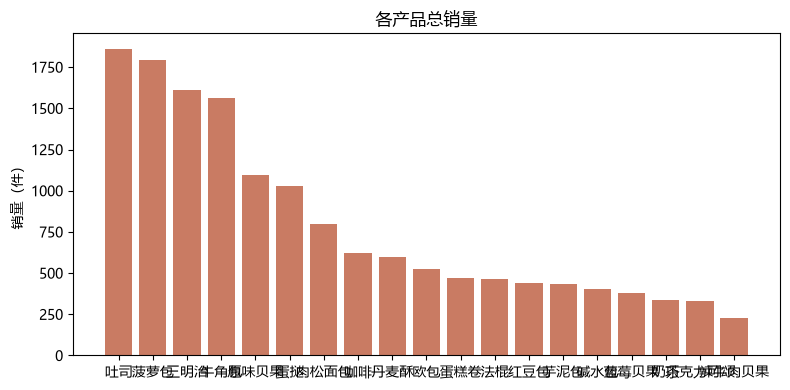

In [4]:
import matplotlib
matplotlib.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
matplotlib.rcParams["axes.unicode_minus"] = False
import matplotlib.pyplot as plt

rank = results["产品偏好"]
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(rank["商品名称"], rank["历史总销量"], color="#C97B63")
ax.set_title("各产品总销量")
ax.set_ylabel("销量（件）")
plt.tight_layout()
plt.show()

## 4. 客流规律与小时工排班

In [5]:
display(results["客流量_分时段"].head(10))
display(results["客流规律_分星期"])
display(results["小时工排班建议"])

,日期,年,月,星期,日期类型,节假日,节假日名称,小时,时段,消费人次,订单数,销量,销售额,客单价,人均消费
0,2026-08-01,2026,202608,六,周末,否,NaN,7,07:00-08:00,3,3,5,40,13.33,13.33
1,2026-08-01,2026,202608,六,周末,否,NaN,8,08:00-09:00,14,14,33,390,27.86,27.86
2,2026-08-01,2026,202608,六,周末,否,NaN,9,09:00-10:00,15,15,45,528,35.20,35.20
3,2026-08-01,2026,202608,六,周末,否,NaN,10,10:00-11:00,9,9,28,292,32.44,32.44
4,2026-08-01,2026,202608,六,周末,否,NaN,12,12:00-13:00,2,2,7,78,39.00,39.00
5,2026-08-01,2026,202608,六,周末,否,NaN,13,13:00-14:00,3,3,4,51,17.00,17.00
6,2026-08-01,2026,202608,六,周末,否,NaN,14,14:00-15:00,5,5,11,91,18.20,18.20
7,2026-08-01,2026,202608,六,周末,否,NaN,15,15:00-16:00,6,6,12,110,18.33,18.33
8,2026-08-01,2026,202608,六,周末,否,NaN,16,16:00-17:00,1,1,5,36,36.00,36.00
9,2026-08-01,2026,202608,六,周末,否,NaN,17,17:00-18:00,4,4,14,147,36.75,36.75


,星期,小时,时段,营业天数,日均消费人次,日均订单数,日均销量,日均销售额,客流占比
0,一,7,07:00-08:00,13,4.62,4.62,10.85,117.54,0.0099
1,一,8,08:00-09:00,13,9.85,9.85,24.38,286.23,0.0211
2,一,9,09:00-10:00,13,6.38,6.38,16.46,184.08,0.0137
3,一,10,10:00-11:00,13,3.46,3.46,9.00,101.62,0.0074
4,一,11,11:00-12:00,13,2.08,2.08,5.15,54.92,0.0045
...,...,...,...,...,...,...,...,...,...
86,日,15,15:00-16:00,13,7.23,7.23,15.31,147.46,0.0155
87,日,16,16:00-17:00,13,6.23,6.23,14.08,139.00,0.0133
88,日,17,17:00-18:00,13,4.23,4.23,9.54,108.69,0.0091
89,日,18,18:00-19:00,13,4.92,4.92,12.00,149.92,0.0105


,星期,小时,时段,日均消费人次,日均订单数,建议在岗人数,建议工时(小时/日),人力成本估算(元/日),排班提示
0,一,7,07:00-08:00,4.62,4.62,1,1,30.0,常规时段
1,一,8,08:00-09:00,9.85,9.85,1,1,30.0,高峰时段（15 人次/人·小时）
2,一,9,09:00-10:00,6.38,6.38,1,1,30.0,高峰时段（15 人次/人·小时）
3,一,10,10:00-11:00,3.46,3.46,1,1,30.0,常规时段
4,一,11,11:00-12:00,2.08,2.08,1,1,30.0,常规时段
...,...,...,...,...,...,...,...,...,...
86,日,15,15:00-16:00,7.23,7.23,1,1,30.0,高峰时段（15 人次/人·小时）
87,日,16,16:00-17:00,6.23,6.23,1,1,30.0,高峰时段（15 人次/人·小时）
88,日,17,17:00-18:00,4.23,4.23,1,1,30.0,常规时段
89,日,18,18:00-19:00,4.92,4.92,1,1,30.0,常规时段


## 5. 节假日效应、原料消耗与采购建议

In [6]:
display(results["节假日效应"])
display(results["原料消耗汇总"])
display(results["原料采购建议"].head(10))
display(results["数据校验"])

,日期类型,天数,日均销量,日均销售额,日均订单数,日均消费人次,销量较工作日
0,工作日,59,126.46,1389.24,51.69,50.71,0.0000
1,周末,22,185.00,2033.05,76.95,75.45,0.4629
2,法定节假日,10,331.70,3634.30,136.20,130.80,1.6230
3,调休上班,1,131.00,1435.00,56.00,56.00,0.0359


,原料名称,计量单位,理论总消耗量,日均消耗量,有消耗天数,消耗量占比,单价,消耗成本估算
0,牛奶,L,962.615,10.463,92,0.8704,12.0,11551.38
1,水,L,131.495,1.429,92,0.1189,2.0,262.99
2,油,L,11.775,0.128,86,0.0106,20.0,235.50
3,面粉,kg,1745.415,18.972,92,0.6772,10.0,17454.15
4,鸡蛋,kg,209.385,2.276,92,0.0812,12.0,2512.62
5,黄油,kg,208.954,2.271,92,0.0811,45.0,9402.93
6,白砂糖,kg,166.868,1.814,92,0.0647,6.0,1001.21
7,奶油,kg,39.380,0.428,92,0.0153,15.0,590.70
8,芝士,kg,30.405,0.330,92,0.0118,60.0,1824.30
9,盐,kg,27.324,0.297,92,0.0106,4.0,109.30


,计划月份,原料名称,计量单位,日均消耗量,预计消耗量,安全库存量,建议采购量,包装规格,单包装含量,建议采购包装数,按包装采购量,单价,预计金额,计算说明
0,2026-11,咖啡豆,kg,0.081,2.43,0.243,2.673,袋,1,3.0,3.0,90.0,270.0,日均消耗 × 当月天数 + 安全库存（3 天日均）
1,2026-11,坚果,kg,0.143,4.29,0.429,4.719,袋,5,1.0,5.0,55.0,275.0,日均消耗 × 当月天数 + 安全库存（3 天日均）
2,2026-11,奶油,kg,0.428,12.84,1.284,14.124,盒,5,3.0,15.0,15.0,225.0,日均消耗 × 当月天数 + 安全库存（3 天日均）
3,2026-11,巧克力,kg,0.072,2.16,0.216,2.376,箱,5,1.0,5.0,65.0,325.0,日均消耗 × 当月天数 + 安全库存（3 天日均）
4,2026-11,果干,kg,0.179,5.37,0.537,5.907,盒,10,1.0,10.0,5.0,50.0,日均消耗 × 当月天数 + 安全库存（3 天日均）
5,2026-11,水,L,1.429,42.87,4.287,47.157,桶,20,3.0,60.0,2.0,120.0,日均消耗 × 当月天数 + 安全库存（3 天日均）
6,2026-11,油,L,0.128,3.84,0.384,4.224,桶,10,1.0,10.0,20.0,200.0,日均消耗 × 当月天数 + 安全库存（3 天日均）
7,2026-11,牛奶,L,10.463,313.89,31.389,345.279,箱,12,29.0,348.0,12.0,4176.0,日均消耗 × 当月天数 + 安全库存（3 天日均）
8,2026-11,牛肉,kg,0.098,2.94,0.294,3.234,袋,5,1.0,5.0,75.0,375.0,日均消耗 × 当月天数 + 安全库存（3 天日均）
9,2026-11,白砂糖,kg,1.814,54.42,5.442,59.862,袋,30,2.0,60.0,6.0,360.0,日均消耗 × 当月天数 + 安全库存（3 天日均）


,校验项,结果,状态
0,购买记录行数,11406 行，可用于计算 11406 行,通过
1,日期缺失,0 行,通过
2,时间缺失（不计入客流）,0 行,通过
3,商品名称缺失,0 行,通过
4,商品编号生成缺失,0 行,通过
5,数量 ≤ 0,0 行,通过
6,消费金额 ≤ 0,0 行,通过
7,完全重复明细,0 行,通过
8,商品名称归一后重名歧义,0 个：无,通过
9,商品信息覆盖全部商品,19 个商品；未覆盖 0 个：无,通过
